# Fashion-MNIST: clasificación de prendas

**Autores:**
- Diego Ubaldo Crespo Neri
- Taban

**Institución:** ITESO

**Carrera:** Ingeniería y Ciencia de Datos

**Asignatura:** Aprendizaje Máquina

**Fecha:** 5 de octubre de 2026

---

## 1. Introducción

Fashion-MNIST (Zalando) contiene 70,000 imágenes de prendas en escala de grises de 28×28 píxeles, 60,000 de entrenamiento y 10,000 de prueba, repartidas en 10 clases. Tiene el mismo formato que MNIST, pero es más difícil.

**Objetivo:** comparar cinco clasificadores (Regresión Logística, SVM, Random Forest, MLP con scikit-learn y CNN con PyTorch) y probarlos con 30 fotos propias (3 por clase).

| 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| T-shirt/top | Trouser | Pullover | Dress | Coat | Sandal | Shirt | Sneaker | Bag | Ankle boot |

## 2. Configuración

Semilla fija y 12 hilos de CPU (el punto óptimo medido en `notes/torch/test2.py`). El estilo de las gráficas se define aquí para que no dependa del `matplotlibrc` local.

In [1]:
# Libraries
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from PIL import Image, ImageOps
from scipy import ndimage
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

SEED = 35
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(12)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR, MODELS_DIR, PHOTOS_DIR = Path("data"), Path("models"), Path("photos")
MODELS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

# Plot style (independent of the local matplotlibrc)
plt.style.use("default")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
BLUE, ORANGE, GRID = "#2a78d6", "#eb6834", "#e1e0d9"

print(f"Dispositivo: {DEVICE}")

Dispositivo: cpu


## 3. Datos

Se usa la partición oficial (60,000 / 10,000). Las imágenes se guardan crudas (`uint8`, 0–255) y cada modelo lleva su propio preprocesamiento, así que una imagen nueva sólo necesita tener el formato del dataset.

In [2]:
train_set = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True)

# Raw images: uint8 (N, 28, 28), values 0-255
img_train, y_train = train_set.data.numpy(), train_set.targets.numpy()
img_test, y_test = test_set.data.numpy(), test_set.targets.numpy()

# Flattened view for scikit-learn: (N, 784)
X_train, X_test = img_train.reshape(-1, 784), img_test.reshape(-1, 784)

print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape} | {X_train.dtype}, rango [{X_train.min()}, {X_train.max()}]")

Entrenamiento: (60000, 784) | Prueba: (10000, 784) | uint8, rango [0, 255]


### 3.1 Análisis exploratorio

In [3]:
counts = pd.DataFrame({"Entrenamiento": np.bincount(y_train), "Prueba": np.bincount(y_test)}, index=CLASS_NAMES)
display(counts.T)
print(f"Media de los píxeles: {img_train.mean():.1f} | desviación: {img_train.std():.1f} | píxeles en 0: {(img_train == 0).mean():.0%}")

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
Entrenamiento,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
Prueba,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


Media de los píxeles: 72.9 | desviación: 90.0 | píxeles en 0: 50%


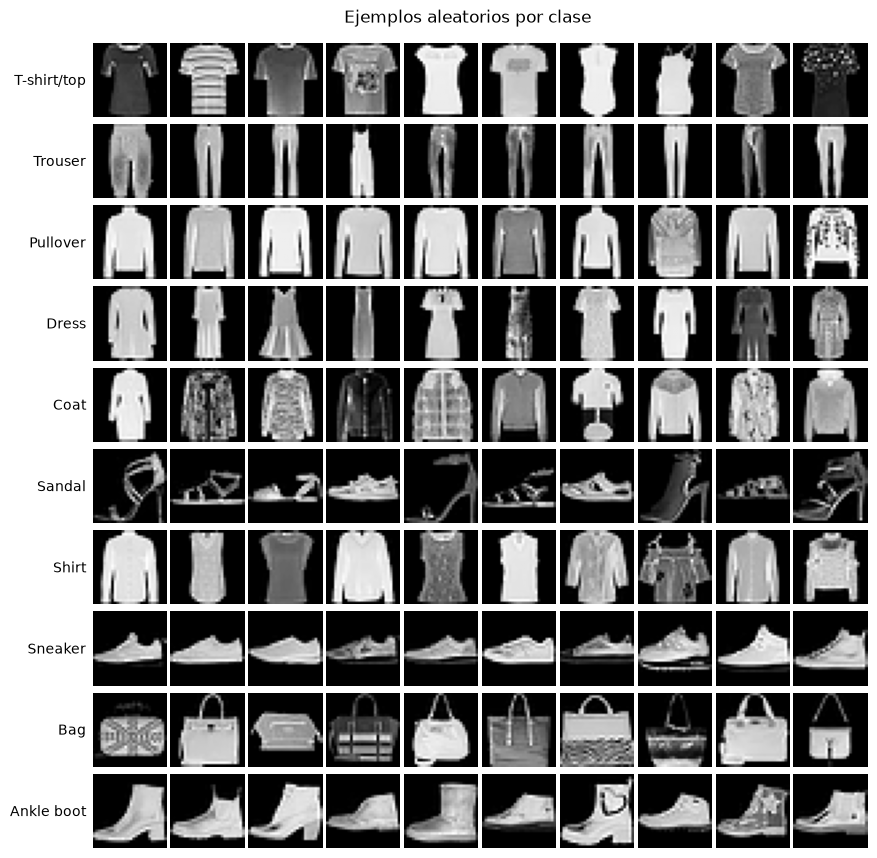

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 10, figsize=(10, 10.5))
for k, name in enumerate(CLASS_NAMES):
    for ax, idx in zip(axes[k], rng.choice(np.flatnonzero(y_train == k), 10, replace=False)):
        ax.imshow(img_train[idx], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
    axes[k, 0].text(-3, 14, name, ha="right", va="center", fontsize=10)
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.suptitle("Ejemplos aleatorios por clase", y=0.91)
plt.show()

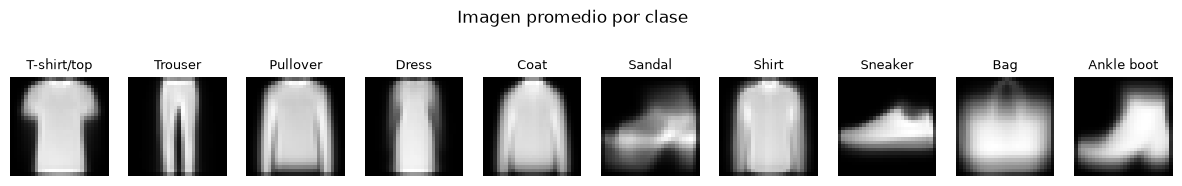

In [5]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for k, ax in enumerate(axes):
    ax.imshow(img_train[y_train == k].mean(axis=0), cmap="gray")
    ax.set_title(CLASS_NAMES[k], fontsize=9)
    ax.axis("off")
plt.suptitle("Imagen promedio por clase", y=1.08)
plt.show()

**Observaciones**
- Las clases están perfectamente balanceadas (6,000 / 1,000 por clase), así que la exactitud es una métrica válida. Se complementa con F1 macro.
- La mitad de los píxeles valen 0: cada objeto es claro, está centrado sobre fondo negro y ocupa todo el alto o todo el ancho de la imagen.
- El calzado siempre apunta a la izquierda (talón o caña a la derecha).
- T-shirt/top, Pullover, Coat y Shirt tienen siluetas promedio casi idénticas; ahí se esperan la mayoría de los errores.

## 4. Metodología

- **Métricas:** exactitud, F1 macro, F1 por clase y matriz de confusión, más los tiempos de entrenamiento y de predicción.
- **Hiperparámetros:** `GridSearchCV` con 3 particiones sobre una submuestra estratificada de 10,000 imágenes de entrenamiento (buscar sobre las 60,000 sería demasiado lento para el SVM). La mejor configuración se reentrena con las 60,000.
- **CNN:** se apartan 6,000 imágenes de entrenamiento como validación para elegir la mejor época.
- **Prueba:** el conjunto de prueba se usa una sola vez por modelo.
- **Caché:** los modelos entrenados se guardan en `models/` para no reentrenarlos al volver a ejecutar el notebook.

In [6]:
results = {}  # model name -> test metrics and predictions


def evaluate(name, y_pred, fit_s, pred_s):
    """Store the test-set metrics of one model."""
    results[name] = {
        "Exactitud": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "Entrenamiento (s)": fit_s,
        "Predicción (s)": pred_s,
        "y_pred": y_pred,
    }
    r = results[name]
    print(f"{name}: exactitud {r['Exactitud']:.4f} | F1 macro {r['F1 macro']:.4f} | "
          f"entrenamiento {fit_s:.0f} s | predicción {pred_s:.1f} s")


# Stratified 10k subsample of the training set, used only for the hyper-parameter search
search_idx, _ = train_test_split(
    np.arange(len(y_train)), train_size=10_000, stratify=y_train, random_state=SEED
)


def tune_and_fit(key, name, pipeline, grid):
    """3-fold grid search on the subsample, refit of the best configuration on all 60k
    images and evaluation on the test set. The fitted model is cached in models/<key>.joblib."""
    path = MODELS_DIR / f"{key}.joblib"
    if path.exists():
        saved = joblib.load(path)
    else:
        search = GridSearchCV(pipeline, grid, cv=3, n_jobs=-1, refit=False)
        search.fit(X_train[search_idx], y_train[search_idx])
        cv_table = pd.DataFrame(search.cv_results_["params"]).rename(columns=lambda c: c.split("__")[-1])
        cv_table["Exactitud CV"] = search.cv_results_["mean_test_score"]

        model = clone(pipeline).set_params(**search.best_params_)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        saved = {"model": model, "cv_table": cv_table, "fit_s": time.perf_counter() - start}
        joblib.dump(saved, path, compress=3)

    cv_table = saved["cv_table"].sort_values("Exactitud CV", ascending=False)
    display(cv_table.style.format({"Exactitud CV": "{:.4f}"}).hide(axis="index"))
    start = time.perf_counter()
    y_pred = saved["model"].predict(X_test)
    evaluate(name, y_pred, saved["fit_s"], time.perf_counter() - start)
    return saved["model"]

## 5. Modelos

### 5.1 Regresión Logística

Modelo lineal: una combinación de los 784 píxeles por clase, seguida de softmax. Sirve como línea base. Se busca la regularización `C`.

In [7]:
logreg = tune_and_fit(
    "logreg", "Regresión Logística",
    Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))]),
    {"clf__C": [0.01, 0.1, 1.0]},
)

C,Exactitud CV
0.010000,0.8363
0.100000,0.8243
1.000000,0.7966


Regresión Logística: exactitud 0.8469 | F1 macro 0.8460 | entrenamiento 139 s | predicción 0.1 s


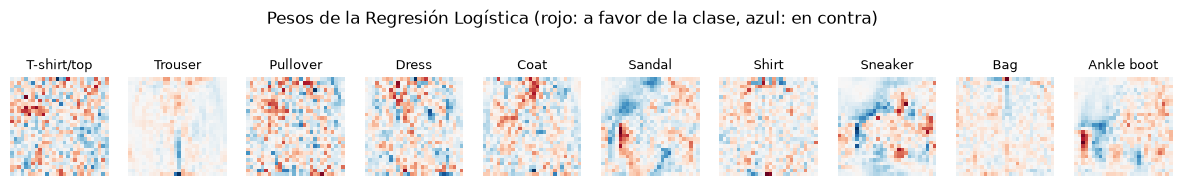

In [8]:
coef = logreg.named_steps["clf"].coef_
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for k, ax in enumerate(axes):
    lim = np.abs(coef[k]).max()
    ax.imshow(coef[k].reshape(28, 28), cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(CLASS_NAMES[k], fontsize=9)
    ax.axis("off")
plt.suptitle("Pesos de la Regresión Logística (rojo: a favor de la clase, azul: en contra)", y=1.08)
plt.show()

Cada clase aprende una sola "plantilla" de píxeles. Un modelo lineal no puede representar variaciones de forma dentro de una misma clase, y eso limita su exactitud.

### 5.2 Random Forest

Un ensamble de árboles de decisión que votan. No necesita escalado, porque cada nodo compara un píxel contra un umbral. Se buscan `max_features` y `min_samples_leaf`.

In [9]:
rf = tune_and_fit(
    "rf", "Random Forest",
    Pipeline([("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED))]),
    {"clf__max_features": ["sqrt", 0.1], "clf__min_samples_leaf": [1, 3]},
)

max_features,min_samples_leaf,Exactitud CV
sqrt,1,0.8517
0.100000,1,0.8508
0.100000,3,0.8500
sqrt,3,0.8494


Random Forest: exactitud 0.8796 | F1 macro 0.8782 | entrenamiento 25 s | predicción 0.3 s


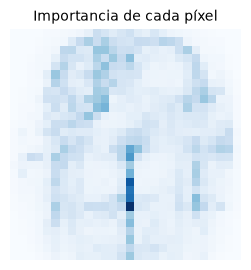

In [10]:
plt.figure(figsize=(3, 3))
plt.imshow(rf.named_steps["clf"].feature_importances_.reshape(28, 28), cmap="Blues")
plt.title("Importancia de cada píxel", fontsize=10)
plt.axis("off")
plt.show()

### 5.3 SVM (kernel RBF)

El costo de entrenar un SVM crece entre n² y n³, así que primero se reduce la dimensión con PCA. No se escala, porque todos los píxeles comparten la escala 0–255 y `gamma="scale"` se adapta a la varianza de los datos. Se buscan el número de componentes y `C`.

In [11]:
svm = tune_and_fit(
    "svm", "SVM (RBF)",
    Pipeline([("pca", PCA(random_state=SEED)), ("clf", SVC(kernel="rbf", cache_size=2000))]),
    {"pca__n_components": [50, 100], "clf__C": [1, 10]},
)
pca = svm.named_steps["pca"]
print(f"PCA: {pca.n_components_} componentes retienen el {pca.explained_variance_ratio_.sum():.1%} de la varianza | "
      f"vectores de soporte: {svm.named_steps['clf'].n_support_.sum():,}")

C,n_components,Exactitud CV
10,100,0.8706
10,50,0.8670
1,100,0.8525
1,50,0.8462


SVM (RBF): exactitud 0.8998 | F1 macro 0.8996 | entrenamiento 70 s | predicción 20.9 s
PCA: 100 componentes retienen el 91.2% de la varianza | vectores de soporte: 17,440


### 5.4 Perceptrón multicapa (scikit-learn)

Red totalmente conectada (ReLU, Adam) con *early stopping* sobre un 10 % interno de validación. Se buscan la arquitectura y la regularización L2 (`alpha`).

In [12]:
mlp = tune_and_fit(
    "mlp", "MLP",
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(early_stopping=True, max_iter=200, random_state=SEED)),
    ]),
    {"clf__hidden_layer_sizes": [(256,), (256, 128)], "clf__alpha": [1e-4, 1e-2]},
)
mlp_clf = mlp.named_steps["clf"]
print(f"Capas ocultas: {mlp_clf.hidden_layer_sizes} | épocas: {mlp_clf.n_iter_} | "
      f"mejor exactitud de validación interna: {mlp_clf.best_validation_score_:.4f}")

alpha,hidden_layer_sizes,Exactitud CV
0.000100,"(256, 128)",0.8512
0.010000,"(256,)",0.8506
0.000100,"(256,)",0.8481
0.010000,"(256, 128)",0.8478


MLP: exactitud 0.8873 | F1 macro 0.8875 | entrenamiento 74 s | predicción 0.1 s


Capas ocultas: (256, 128) | épocas: 24 | mejor exactitud de validación interna: 0.9042


### 5.5 Red neuronal convolucional (PyTorch)

Se usa la arquitectura vista en clase:
- 2 bloques Conv 3×3 → BatchNorm → ReLU → MaxPool (28 → 14 → 7);
- una cabeza densa 3136 → 128 → 10 con Dropout(0.3).

Entrenamiento:
- entradas normalizadas con la media y la desviación del entrenamiento;
- volteo horizontal aleatorio como aumento de datos (una prenda reflejada sigue siendo de la misma clase);
- Adam (lr = 0.001), lotes de 64 y 15 épocas, conservando la época con mejor exactitud de validación.

In [13]:
# Normalisation statistics from the training set only
MEAN, STD = float(img_train.mean() / 255), float(img_train.std() / 255)


def to_tensor(images):
    """uint8 (N, 28, 28) -> normalised float tensor (N, 1, 28, 28)."""
    x = torch.from_numpy(images).float().div(255).unsqueeze(1)
    return (x - MEAN) / STD


def make_loader(images, labels, shuffle=False, batch_size=512):
    return DataLoader(TensorDataset(to_tensor(images), torch.from_numpy(labels)),
                      batch_size=batch_size, shuffle=shuffle)


# 54k train / 6k validation (stratified); the test set stays untouched until the end
tr_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=6_000, stratify=y_train, random_state=SEED
)
train_loader = make_loader(img_train[tr_idx], y_train[tr_idx], shuffle=True, batch_size=64)
val_loader = make_loader(img_train[val_idx], y_train[val_idx])
print(f"Media {MEAN:.4f} | desviación {STD:.4f} | {len(tr_idx):,} entrenamiento, {len(val_idx):,} validación")

Media 0.2860 | desviación 0.3530 | 54,000 entrenamiento, 6,000 validación


In [14]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 32 x 28 x 28
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 64 x 14 x 14
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 64 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = FashionCNN().to(DEVICE)

# Parameters per layer, compared with the MLP
layers = {
    f"{name} · {type(m).__name__}": sum(p.numel() for p in m.parameters())
    for name, m in cnn.named_modules()
    if not list(m.children()) and any(True for _ in m.parameters())
}
display(pd.Series(layers, name="Parámetros").to_frame())
print(f"Total CNN: {sum(layers.values()):,} | Total MLP: {sum(w.size for w in mlp_clf.coefs_ + mlp_clf.intercepts_):,}")

,Parámetros
features.0 · Conv2d,320
features.1 · BatchNorm2d,64
features.4 · Conv2d,18496
features.5 · BatchNorm2d,128
classifier.1 · Linear,401536
classifier.4 · Linear,1290


Total CNN: 421,834 | Total MLP: 235,146


La CNN tiene más parámetros que el MLP (422k contra 235k), pero el 95 % están en la primera capa densa. Las dos convoluciones suman apenas 19k, porque cada filtro de 3×3 se comparte en toda la imagen.

In [15]:
criterion = nn.CrossEntropyLoss()


def run_epoch(model, loader, optimizer=None):
    """One pass over `loader`; trains when an optimizer is given. Returns (loss, accuracy)."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct = 0.0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:  # data augmentation: random horizontal flip
                flip = torch.rand(len(x), device=DEVICE) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(-1), x)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(dim=1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

In [16]:
EPOCHS = 15
cnn_path, history_path = MODELS_DIR / "cnn.pt", MODELS_DIR / "cnn_history.json"


def log_epoch(h, i):
    print(f"Época {i + 1:2d} | pérdida entrenamiento {h['train_loss'][i]:.4f} | "
          f"pérdida validación {h['val_loss'][i]:.4f} | exactitud validación {h['val_acc'][i]:.4f}")


if cnn_path.exists() and history_path.exists():
    history = json.loads(history_path.read_text())
    for i in range(len(history["val_acc"])):
        log_epoch(history, i)
else:
    optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        train_loss, train_acc = run_epoch(cnn, train_loader, optimizer)
        val_loss, val_acc = run_epoch(cnn, val_loader)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        if val_acc == max(history["val_acc"]):  # keep the best epoch (manual early stopping)
            torch.save(cnn.state_dict(), cnn_path)
        log_epoch(history, epoch)
    history["fit_s"] = time.perf_counter() - start
    history_path.write_text(json.dumps(history))

cnn.load_state_dict(torch.load(cnn_path, map_location=DEVICE))
best_epoch = int(np.argmax(history["val_acc"])) + 1
print(f"Mejor época: {best_epoch} (exactitud de validación {max(history['val_acc']):.4f})")

Época  1 | pérdida entrenamiento 0.4832 | pérdida validación 0.3169 | exactitud validación 0.8867
Época  2 | pérdida entrenamiento 0.3340 | pérdida validación 0.2882 | exactitud validación 0.8898
Época  3 | pérdida entrenamiento 0.2921 | pérdida validación 0.2630 | exactitud validación 0.9023
Época  4 | pérdida entrenamiento 0.2691 | pérdida validación 0.2600 | exactitud validación 0.9027
Época  5 | pérdida entrenamiento 0.2510 | pérdida validación 0.2389 | exactitud validación 0.9135
Época  6 | pérdida entrenamiento 0.2341 | pérdida validación 0.2586 | exactitud validación 0.9063
Época  7 | pérdida entrenamiento 0.2225 | pérdida validación 0.2338 | exactitud validación 0.9138
Época  8 | pérdida entrenamiento 0.2099 | pérdida validación 0.2439 | exactitud validación 0.9148
Época  9 | pérdida entrenamiento 0.1976 | pérdida validación 0.2283 | exactitud validación 0.9195
Época 10 | pérdida entrenamiento 0.1889 | pérdida validación 0.2139 | exactitud validación 0.9272
Época 11 | pérdida e

In [17]:
@torch.no_grad()
def cnn_predict_proba(images, batch_size=1000):
    """Class probabilities for raw uint8 images (N, 28, 28)."""
    cnn.eval()
    probs = [torch.softmax(cnn(to_tensor(images[i:i + batch_size]).to(DEVICE)), dim=1)
             for i in range(0, len(images), batch_size)]
    return torch.cat(probs).cpu().numpy()


start = time.perf_counter()
y_pred_cnn = cnn_predict_proba(img_test).argmax(axis=1)
evaluate("CNN", y_pred_cnn, history["fit_s"], time.perf_counter() - start)

CNN: exactitud 0.9249 | F1 macro 0.9242 | entrenamiento 387 s | predicción 1.9 s


## 6. Resultados

In [18]:
FORMATS = {"Exactitud": "{:.2%}", "F1 macro": "{:.4f}", "Entrenamiento (s)": "{:.0f}",
           "Predicción (s)": "{:.1f}", "Exactitud fotos": "{:.0%}"}


def show_summary(df):
    display(df.style.format({c: f for c, f in FORMATS.items() if c in df}))


summary = (pd.DataFrame(results).T.drop(columns="y_pred").astype(float)
           .sort_values("Exactitud", ascending=False))
show_summary(summary)

,Exactitud,F1 macro,Entrenamiento (s),Predicción (s)
CNN,92.49%,0.9242,387,1.9
SVM (RBF),89.98%,0.8996,70,20.9
MLP,88.73%,0.8875,74,0.1
Random Forest,87.96%,0.8782,25,0.3
Regresión Logística,84.69%,0.8460,139,0.1


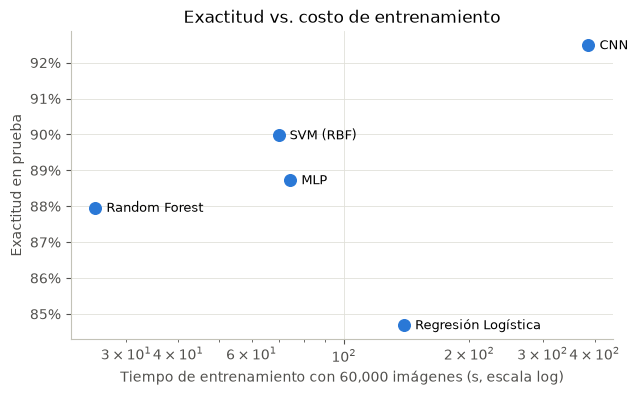

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(summary["Entrenamiento (s)"], summary["Exactitud"], s=70, color=BLUE, zorder=3)
for name, row in summary.iterrows():
    ax.annotate(name, (row["Entrenamiento (s)"], row["Exactitud"]),
                xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(color=GRID, linewidth=0.6)
ax.set(xlabel="Tiempo de entrenamiento con 60,000 imágenes (s, escala log)",
       ylabel="Exactitud en prueba", title="Exactitud vs. costo de entrenamiento")
plt.show()

**F1 por clase** (en prueba):

In [20]:
per_class = pd.DataFrame(
    {name: f1_score(y_test, r["y_pred"], average=None) for name, r in results.items()},
    index=CLASS_NAMES,
)[summary.index]
display(per_class.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))

,CNN,SVM (RBF),MLP,Random Forest,Regresión Logística
T-shirt/top,0.880,0.849,0.836,0.843,0.812
Trouser,0.990,0.981,0.980,0.980,0.966
Pullover,0.889,0.824,0.816,0.789,0.738
Dress,0.923,0.906,0.893,0.893,0.854
Coat,0.882,0.833,0.808,0.795,0.750
Sandal,0.984,0.969,0.961,0.968,0.935
Shirt,0.778,0.733,0.718,0.655,0.599
Sneaker,0.966,0.956,0.944,0.941,0.924
Bag,0.981,0.978,0.969,0.965,0.939
Ankle boot,0.970,0.966,0.952,0.952,0.944


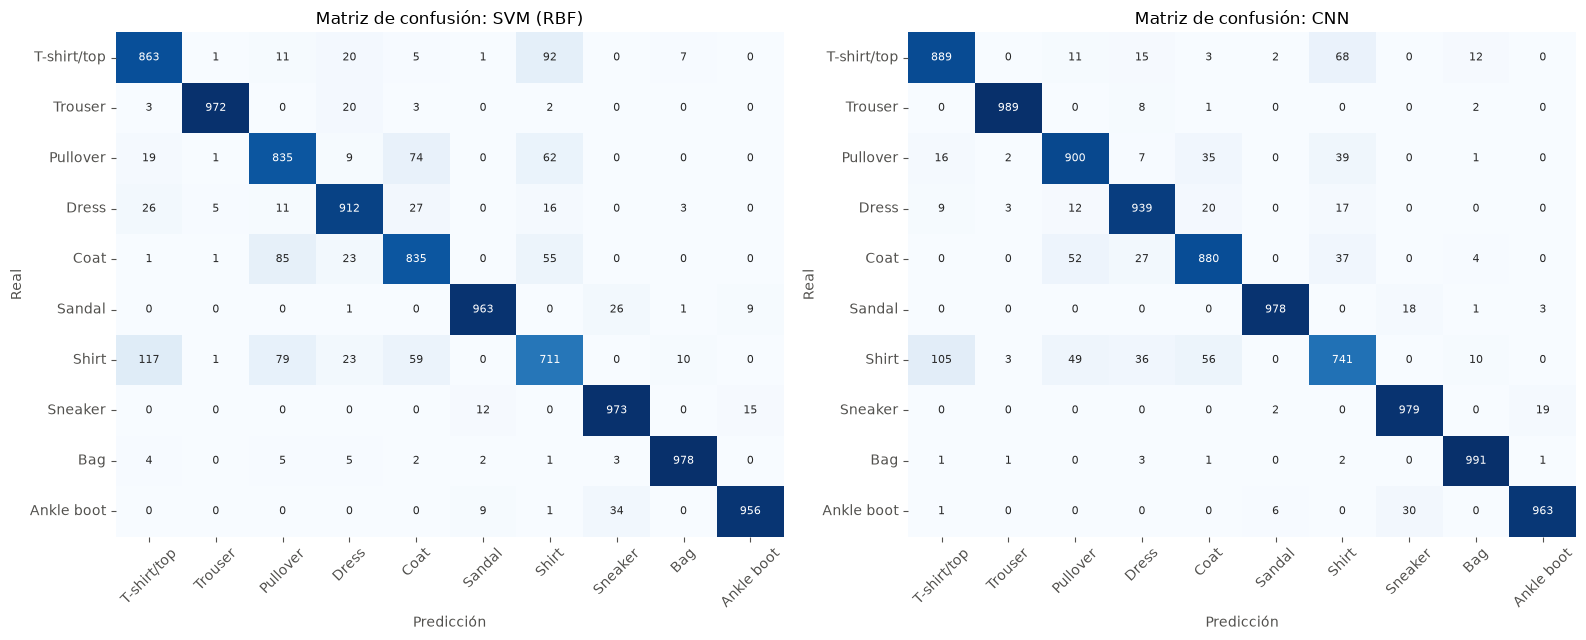

In [21]:
best_classic = summary.index.drop("CNN")[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, name in zip(axes, [best_classic, "CNN"]):
    cm = confusion_matrix(y_test, results[name]["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8},
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(title=f"Matriz de confusión: {name}", xlabel="Predicción", ylabel="Real")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# Most frequent confusions of the CNN
cm = confusion_matrix(y_test, y_pred_cnn)
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm, axis=None)[::-1][:6], cm.shape))[0]
display(pd.DataFrame([(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i, j in top],
                     columns=["Real", "Predicción", "Errores"]).style.hide(axis="index"))

Real,Predicción,Errores
Shirt,T-shirt/top,105
T-shirt/top,Shirt,68
Shirt,Coat,56
Coat,Pullover,52
Shirt,Pullover,49
Pullover,Shirt,39


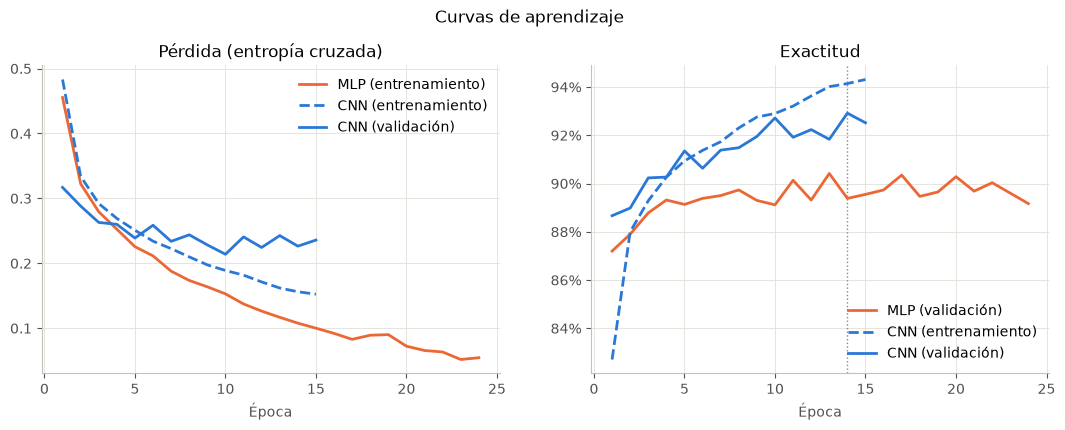

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep_mlp = np.arange(1, mlp_clf.n_iter_ + 1)
ep_cnn = np.arange(1, len(history["val_acc"]) + 1)

axes[0].plot(ep_mlp, mlp_clf.loss_curve_, color=ORANGE, lw=2, label="MLP (entrenamiento)")
axes[0].plot(ep_cnn, history["train_loss"], color=BLUE, lw=2, ls="--", label="CNN (entrenamiento)")
axes[0].plot(ep_cnn, history["val_loss"], color=BLUE, lw=2, label="CNN (validación)")
axes[0].set(title="Pérdida (entropía cruzada)", xlabel="Época")

axes[1].plot(ep_mlp, mlp_clf.validation_scores_, color=ORANGE, lw=2, label="MLP (validación)")
axes[1].plot(ep_cnn, history["train_acc"], color=BLUE, lw=2, ls="--", label="CNN (entrenamiento)")
axes[1].plot(ep_cnn, history["val_acc"], color=BLUE, lw=2, label="CNN (validación)")
axes[1].axvline(best_epoch, color="#898781", lw=1, ls=":")
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set(title="Exactitud", xlabel="Época")

for ax in axes:
    ax.grid(color=GRID, linewidth=0.6)
    ax.legend(frameon=False)
plt.suptitle("Curvas de aprendizaje", y=1.02)
plt.show()

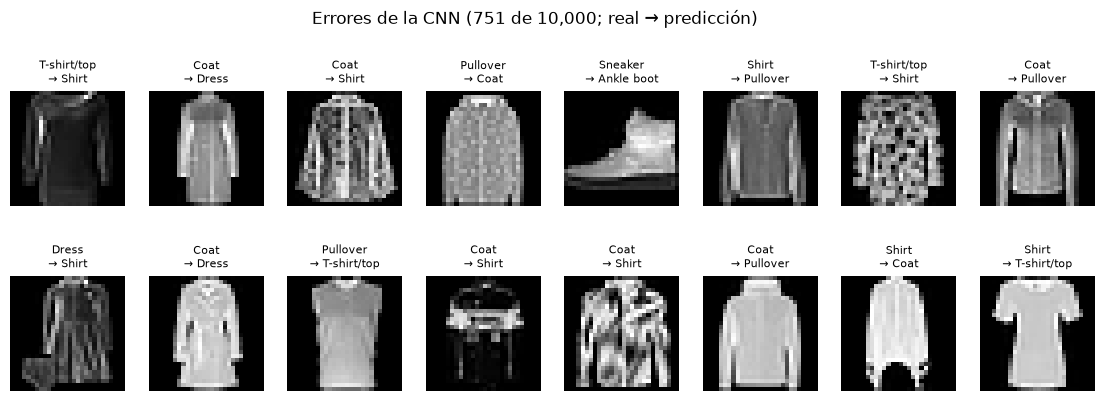

In [24]:
wrong = np.flatnonzero(y_pred_cnn != y_test)
fig, axes = plt.subplots(2, 8, figsize=(14, 4.4))
for ax, idx in zip(axes.ravel(), np.random.default_rng(SEED).choice(wrong, 16, replace=False)):
    ax.imshow(img_test[idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[y_test[idx]]}\n→ {CLASS_NAMES[y_pred_cnn[idx]]}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Errores de la CNN ({len(wrong)} de {len(y_test):,}; real → predicción)", y=1.02)
plt.show()

**Análisis**
- **La CNN gana** con 92.5 % de exactitud, seguida del SVM (90.0 %), el MLP (88.7 %), Random Forest (88.0 %) y la Regresión Logística (84.7 %). La CNN es el único modelo que aprovecha la vecindad entre píxeles; los demás ven un vector plano de 784 valores.
- **Costo:** Random Forest es el más rápido de entrenar (25 s) y queda a menos de un punto del MLP. El SVM es el más lento al predecir (~20 s), porque cada imagen se compara contra 17,440 vectores de soporte. La CNN tarda ~6.5 min en CPU.
- **Shirt es la clase más difícil para todos los modelos** (F1 entre 0.60 y 0.78). Se confunde sobre todo con T-shirt/top, Coat y Pullover, como anticipaban las siluetas promedio del EDA. Trouser, Sandal, Sneaker, Bag y Ankle boot superan 0.92 de F1 en todos los modelos.
- **Curvas de aprendizaje:** la pérdida de entrenamiento de ambas redes sigue bajando, pero la de validación de la CNN se estanca desde la época 10 (inicio del sobreajuste), y por eso se conserva la mejor época (14). El MLP se detiene por *early stopping* en la época 24, con ~90 % de exactitud de validación.
- Varios errores de la CNN serían ambiguos incluso para una persona (camisa vs. playera, abrigo vs. suéter a 28×28).

## 7. Fotos propias

Son 30 fotos (3 por clase) tomadas sobre una sábana verde. Zalando generó Fashion-MNIST así: recortar el fondo → llevar el lado mayor a 28 px → centrar en 28×28 → invertir → pasar a escala de grises. Como aquí el fondo es verde y no blanco, invertir los grises no basta: la sábana quedaría gris claro. Por eso el objeto se separa por **color**:

1. **Máscara:** distancia de cromaticidad (el color sin el brillo, que así ignora las sombras de la sábana) entre cada píxel y el borde de la foto, con umbral de Otsu. Se limpia con una apertura, conservando el componente más grande y rellenando huecos. Si la máscara sale casi vacía (una prenda del color del fondo), se usa la distancia en RGB.
2. Grises invertidos dentro de la máscara; fondo en 0.
3. Recorte al objeto y contraste estirado a 0–255.
4. Lado mayor a 28 px, centrado en un lienzo negro de 28×28.
5. Si el lado izquierdo es más alto que el derecho, la imagen se refleja, porque el calzado del dataset apunta a la izquierda. Esta regla no usa la etiqueta y no cambia las prendas simétricas.

In [25]:
def otsu_threshold(values):
    """Otsu's method: the threshold that maximises the between-class variance."""
    hist, edges = np.histogram(values, bins=256)
    p = hist / hist.sum()
    centers = (edges[:-1] + edges[1:]) / 2
    w0, mu = np.cumsum(p), np.cumsum(p * centers)
    between = (mu[-1] * w0 - mu) ** 2 / (w0 * (1 - w0) + 1e-12)
    return centers[np.argmax(between)]


def object_mask(features, border_px):
    """Pixels far from the background colour (median of the photo border), cleaned up."""
    edge = np.concatenate([
        features[:border_px].reshape(-1, 3), features[-border_px:].reshape(-1, 3),
        features[:, :border_px].reshape(-1, 3), features[:, -border_px:].reshape(-1, 3),
    ])
    dist = np.linalg.norm(features - np.median(edge, axis=0), axis=2)
    mask = ndimage.binary_opening(dist > otsu_threshold(dist), iterations=3)
    labels, n = ndimage.label(mask)
    if n == 0:
        return mask
    largest = np.argmax(np.bincount(labels.ravel())[1:]) + 1
    return ndimage.binary_fill_holes(labels == largest)


def preprocess_photo(path):
    """Phone photo -> 28x28 uint8 image in raw Fashion-MNIST format."""
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((512, 512))
    rgb = np.asarray(im, dtype=float)
    border_px = rgb.shape[0] // 20

    # 1. Object mask by colour (chromaticity ignores the lighting gradient of the sheet)
    chroma = rgb / (rgb.sum(axis=2, keepdims=True) + 1e-6)
    mask = object_mask(chroma, border_px)
    if mask.mean() < 0.05:  # item has the background's colour -> fall back to RGB
        mask = object_mask(rgb, border_px)

    # 2. Inverted grey levels inside the mask, black background
    grey = 255 - np.asarray(im.convert("L"), dtype=float)
    grey[~mask] = 0

    # 3. Crop to the object and stretch its contrast to 0-255
    rows, cols = np.where(mask)
    grey = grey[rows.min():rows.max() + 1, cols.min():cols.max() + 1]
    grey = np.clip(grey * 255 / np.percentile(grey[grey > 0], 99), 0, 255)

    # 4. Longest side -> 28 px, centred on a 28x28 black canvas
    obj = Image.fromarray(grey.astype(np.uint8))
    obj.thumbnail((28, 28), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(obj, ((28 - obj.width) // 2, (28 - obj.height) // 2))
    out = np.asarray(canvas, dtype=np.uint8)

    # 5. Dataset footwear points left (tall side on the right): mirror if needed
    height = (out > 30).sum(axis=0)
    if height[:9].sum() > height[-9:].sum():
        out = out[:, ::-1].copy()
    return out

In [26]:
PHOTO_FOLDERS = {"top": 0, "trouser": 1, "pullover": 2, "dress": 3, "coat": 4,
                 "sandal": 5, "shirt": 6, "sneaker": 7, "bag": 8, "ankle_boot": 9}
(PHOTOS_DIR / "processed").mkdir(exist_ok=True)

photo_ids, photo_paths, photo_labels, photo_images = [], [], [], []
for folder, label in PHOTO_FOLDERS.items():
    for i, path in enumerate(sorted((PHOTOS_DIR / "raw" / folder).glob("*.jpg")), start=1):
        image = preprocess_photo(path)
        Image.fromarray(image).save(PHOTOS_DIR / "processed" / f"{folder}_{i}.png")
        photo_ids.append(f"{folder}_{i}")
        photo_paths.append(path)
        photo_labels.append(label)
        photo_images.append(image)

y_photos, img_photos = np.array(photo_labels), np.stack(photo_images)
print(f"{len(img_photos)} fotos procesadas → {img_photos.shape}, guardadas en photos/processed/")

30 fotos procesadas → (30, 28, 28), guardadas en photos/processed/


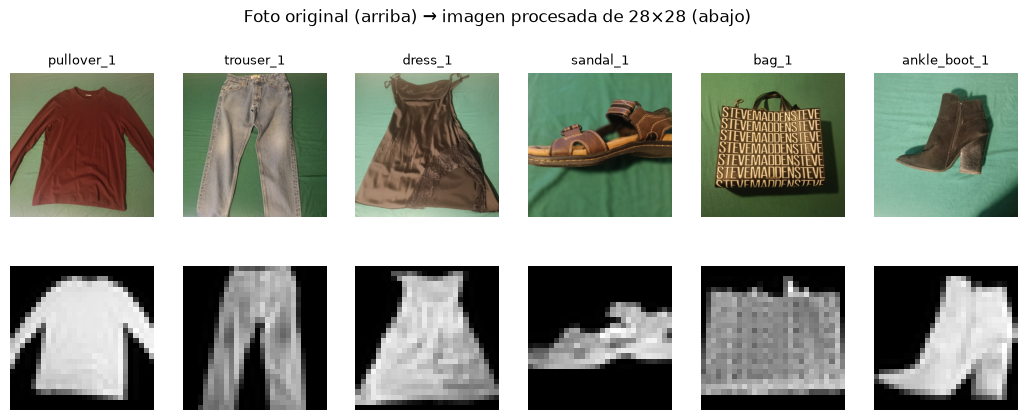

In [27]:
examples = [photo_ids.index(f"{c}_1") for c in ["pullover", "trouser", "dress", "sandal", "bag", "ankle_boot"]]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for col, i in enumerate(examples):
    raw = ImageOps.exif_transpose(Image.open(photo_paths[i]))
    raw.thumbnail((300, 300))
    axes[0, col].imshow(raw)
    axes[0, col].set_title(photo_ids[i], fontsize=9)
    axes[1, col].imshow(img_photos[i], cmap="gray", vmin=0, vmax=255)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Foto original (arriba) → imagen procesada de 28×28 (abajo)", y=1.0)
plt.show()

In [28]:
sk_models = {"Regresión Logística": logreg, "Random Forest": rf, "SVM (RBF)": svm, "MLP": mlp}
photo_preds = {name: model.predict(img_photos.reshape(-1, 784)) for name, model in sk_models.items()}
proba_photos = cnn_predict_proba(img_photos)
photo_preds["CNN"] = proba_photos.argmax(axis=1)

table = pd.DataFrame({"Real": [CLASS_NAMES[k] for k in y_photos]}, index=photo_ids)
for name, pred in photo_preds.items():
    table[name] = [("✓ " if p == t else "✗ ") + CLASS_NAMES[p] for p, t in zip(pred, y_photos)]
top3 = np.argsort(-proba_photos, axis=1)[:, :3]
table["CNN top-3"] = [", ".join(f"{CLASS_NAMES[k]} {proba_photos[i, k]:.0%}" for k in row)
                      for i, row in enumerate(top3)]
display(table)

,Real,Regresión Logística,Random Forest,SVM (RBF),MLP,CNN,CNN top-3
top_1,T-shirt/top,✗ Shirt,✗ Shirt,✗ Shirt,✗ Shirt,✗ Shirt,"Shirt 52%, T-shirt/top 46%, Bag 2%"
top_2,T-shirt/top,✗ Shirt,✗ Shirt,✗ Shirt,✗ Bag,✗ Shirt,"Shirt 87%, Coat 7%, Dress 3%"
top_3,T-shirt/top,✗ Shirt,✗ Shirt,✗ Shirt,✗ Shirt,✗ Shirt,"Shirt 86%, T-shirt/top 13%, Bag 1%"
trouser_1,Trouser,✓ Trouser,✓ Trouser,✓ Trouser,✓ Trouser,✓ Trouser,"Trouser 100%, Coat 0%, Pullover 0%"
trouser_2,Trouser,✗ Bag,✗ Bag,✗ Pullover,✗ Shirt,✗ Shirt,"Shirt 38%, Bag 28%, Coat 19%"
trouser_3,Trouser,✓ Trouser,✓ Trouser,✓ Trouser,✓ Trouser,✓ Trouser,"Trouser 100%, Coat 0%, T-shirt/top 0%"
pullover_1,Pullover,✗ Bag,✗ Bag,✗ Bag,✗ Bag,✗ Bag,"Bag 100%, Shirt 0%, T-shirt/top 0%"
pullover_2,Pullover,✗ Bag,✗ Shirt,✗ Bag,✗ Bag,✗ Bag,"Bag 97%, Shirt 1%, T-shirt/top 1%"
pullover_3,Pullover,✗ Bag,✗ Bag,✗ Bag,✗ Bag,✗ Shirt,"Shirt 92%, Bag 5%, T-shirt/top 2%"
dress_1,Dress,✗ Coat,✗ Coat,✓ Dress,✗ Shirt,✓ Dress,"Dress 90%, Shirt 4%, T-shirt/top 3%"


In [29]:
summary["Exactitud fotos"] = pd.Series({name: (pred == y_photos).mean() for name, pred in photo_preds.items()})
show_summary(summary)

hits = pd.DataFrame(
    {name: np.bincount(y_photos[pred == y_photos], minlength=10) for name, pred in photo_preds.items()},
    index=CLASS_NAMES,
)[summary.index]
print("Aciertos por clase en las fotos (de 3):")
display(hits.style.background_gradient(cmap="Blues", vmin=0, vmax=3))

,Exactitud,F1 macro,Entrenamiento (s),Predicción (s),Exactitud fotos
CNN,92.49%,0.9242,387,1.9,50%
SVM (RBF),89.98%,0.8996,70,20.9,43%
MLP,88.73%,0.8875,74,0.1,47%
Random Forest,87.96%,0.8782,25,0.3,43%
Regresión Logística,84.69%,0.8460,139,0.1,40%


Aciertos por clase en las fotos (de 3):


,CNN,SVM (RBF),MLP,Random Forest,Regresión Logística
T-shirt/top,0,0,0,0,0
Trouser,2,2,2,2,2
Pullover,0,0,0,0,0
Dress,2,1,0,0,0
Coat,0,0,1,0,0
Sandal,1,1,1,1,1
Shirt,1,0,1,1,0
Sneaker,3,3,3,3,3
Bag,3,3,3,3,3
Ankle boot,3,3,3,3,3


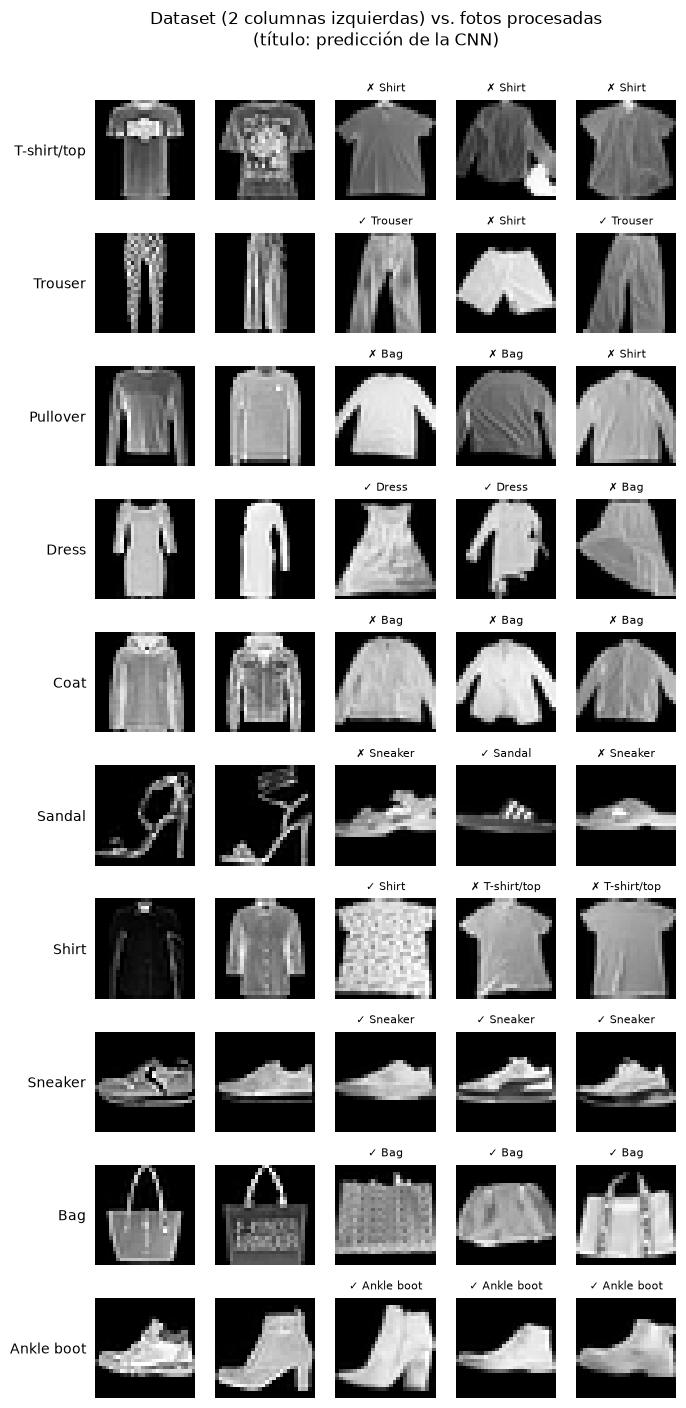

In [30]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 5, figsize=(7.5, 17))
for k, name in enumerate(CLASS_NAMES):
    photos = np.flatnonzero(y_photos == k)
    samples = rng.choice(np.flatnonzero(y_train == k), 2, replace=False)
    for ax, image in zip(axes[k], [*img_train[samples], *img_photos[photos]]):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
    for ax, i in zip(axes[k, 2:], photos):
        pred = photo_preds["CNN"][i]
        ax.set_title(f"{'✓' if pred == k else '✗'} {CLASS_NAMES[pred]}", fontsize=8)
    axes[k, 0].text(-3, 14, name, ha="right", va="center", fontsize=10)
plt.suptitle("Dataset (2 columnas izquierdas) vs. fotos procesadas\n(título: predicción de la CNN)", y=0.93)
plt.show()

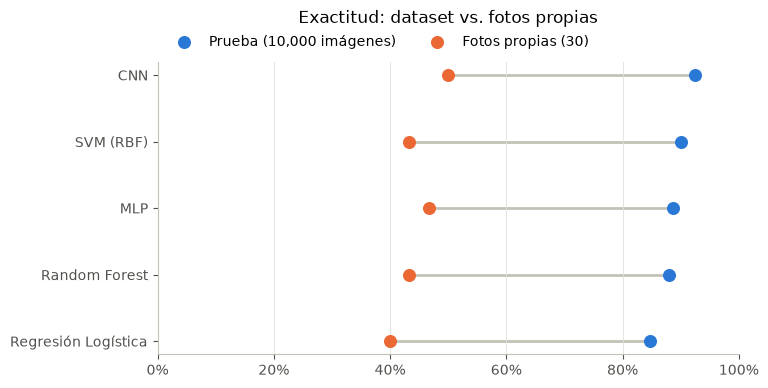

In [31]:
order = summary.index[::-1]
ypos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hlines(ypos, summary.loc[order, "Exactitud fotos"], summary.loc[order, "Exactitud"],
          color="#c3c2b7", lw=2, zorder=1)
ax.scatter(summary.loc[order, "Exactitud"], ypos, s=70, color=BLUE, zorder=3, label="Prueba (10,000 imágenes)")
ax.scatter(summary.loc[order, "Exactitud fotos"], ypos, s=70, color=ORANGE, zorder=3, label="Fotos propias (30)")
ax.set_yticks(ypos, order)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Exactitud: dataset vs. fotos propias", pad=28)
plt.show()

**Análisis de las fotos**
- **La CNN es la más robusta:** acierta 15 de 30 fotos (50 %), contra 40–47 % del resto. Todos los modelos pierden 40–50 puntos respecto al conjunto de prueba, una muestra clara de **cambio de distribución** (iluminación, textura, ángulo y forma de acomodar la prenda).
- **Calzado y bolsas funcionan casi perfecto:** sneakers, bolsas y botines aciertan 3/3 en todos los modelos, porque son objetos rígidos con una silueta estable.
- **Pullover y Coat se clasifican como Bag:** en el dataset las mangas cuelgan a los costados y la prenda es más alta que ancha. En las fotos, en cambio, las mangas están extendidas y la silueta queda casi cuadrada y rellena, como una bolsa. Fotografiar las prendas colgadas, como en el catálogo de Zalando, probablemente lo corregiría.
- **Etiquetas discutibles:** `top/` contiene dos camisas con botones (la CNN las clasifica como Shirt con 86–87 %), y `shirt/` contiene dos playeras sin botones. Con esas etiquetas corregidas, la CNN acertaría 17/30. Además, `trouser_2` es un short y `dress_3` es una falda, y ninguno se parece a los ejemplos del dataset.
- **Sandalias:** las dos sandalias cafés tienen suela gruesa y salen cortadas por el borde de la foto. A 28×28 se parecen más a un sneaker que a las sandalias del dataset, muchas de tacón y tiras delgadas.

## 8. Conclusiones

- **La CNN es el mejor modelo**, tanto en prueba (92.5 %) como con fotos reales (50 %). Sus convoluciones capturan la estructura espacial con pocos parámetros, algo que ningún modelo sobre píxeles aplanados puede hacer.
- **El SVM es la mejor alternativa clásica** (90.0 %) si antes se reduce la dimensión con PCA. **Random Forest** ofrece la mejor relación entre exactitud y tiempo de entrenamiento.
- **La dificultad está en las prendas superiores:** Shirt, T-shirt/top, Pullover y Coat concentran la mayoría de los errores de todos los modelos.
- **Una buena exactitud en prueba no garantiza buen desempeño en el mundo real:** con fotos propias, la exactitud cae a 40–50 %. El preprocesamiento (máscara por color, recorte, inversión) y la forma de fotografiar importan tanto como el modelo.
- **Siguientes pasos:** fotografiar las prendas colgadas y completas, corregir las etiquetas dudosas y entrenar la CNN con más aumento de datos (traslaciones, rotaciones y cambios de contraste) para hacerla más robusta ante fotos reales.